In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from IPython.display import display, Markdown

df = pd.read_excel('Пренатальная диагностика.xlsx')
df.columns = [str(c).strip() for c in df.columns]
display(df.head())

,vozrast,gr-dni,ctr,nt,rost,ves,"pol(1-м, 0-д)"
0,18,70,61,1.3,48,3100,0
1,22,72,50,0.9,50,3400,0
2,29,73,45,0.9,53,3500,1
3,28,74,47,1.1,50,3490,1
4,31,74,46,1.3,53,3590,0


Найти, сколько родилось мальчиков и девочек.

In [2]:
counts = df['pol(1-м, 0-д)'].value_counts().sort_index()
print(f"Девочек (0): {counts.get(0, 0)}")
print(f"Мальчиков (1): {counts.get(1, 0)}")

Девочек (0): 473
Мальчиков (1): 577


Добавить столбец ИМТ (индекс массы тела)

In [3]:
df['imt'] = df['ves'] / ((df['rost'] / 100) ** 2)
display(df[['rost', 'ves', 'imt']].head())

,rost,ves,imt
0,48,3100,13454.861111
1,50,3400,13600.000000
2,53,3500,12459.950160
3,50,3490,13960.000000
4,53,3590,12780.348879


Найти числовые характеристики для всех показателей (минимум, максимум, размах, среднее, медиана и т.д.).

In [4]:
numeric_cols = df.select_dtypes(include=np.number).columns

stats_df = pd.DataFrame({
    'min': df[numeric_cols].min(),
    'max': df[numeric_cols].max(),
    'range': df[numeric_cols].max() - df[numeric_cols].min(),
    'mean': df[numeric_cols].mean().round(3),
    'median': df[numeric_cols].median(),
    'std': df[numeric_cols].std().round(3),
})
display(stats_df)

,min,max,range,mean,median,std
vozrast,16.000000,45.000000,29.000000,28.682,28.000000,5.406
gr-dni,70.000000,108.000000,38.000000,88.765,88.000000,6.315
ctr,45.000000,85.000000,40.000000,64.126,64.000000,10.450
nt,0.300000,2.800000,2.500000,1.337,1.300000,0.398
rost,45.000000,60.000000,15.000000,51.698,52.000000,2.087
ves,2410.000000,5040.000000,2630.000000,3435.779,3430.000000,399.315
"pol(1-м, 0-д)",0.000000,1.000000,1.000000,0.550,1.000000,0.498
imt,8686.365255,18117.451062,9431.085808,12829.898,12801.384083,1017.828


    5. Проверить все показатели на нормальность (распределение Гаусса)
        a. гистограмма или kde (визуальная оценка)
        b. асимметрия и эксцесс (чему должны равняться при нормальном распределении?)
        c.  критерий нормальности (можно взять уровень значимости =0,05)

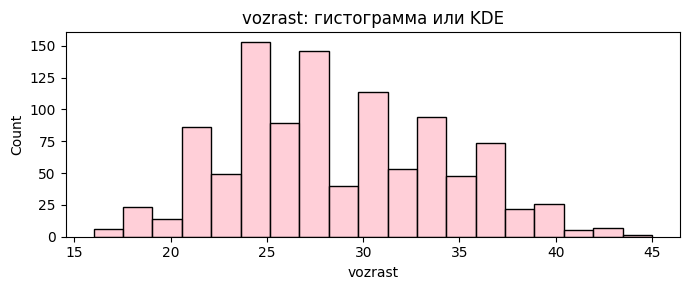

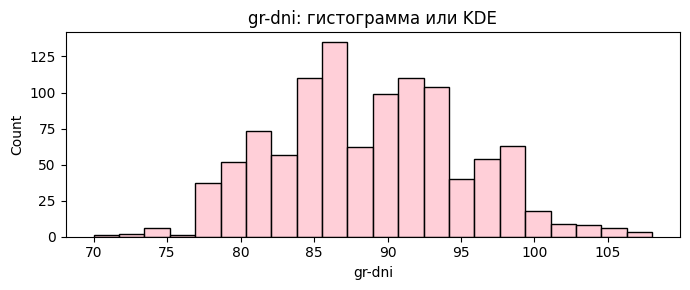

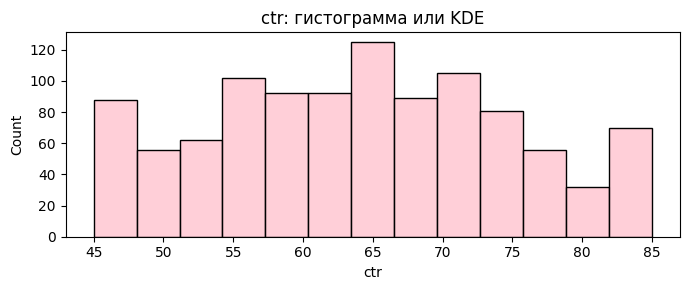

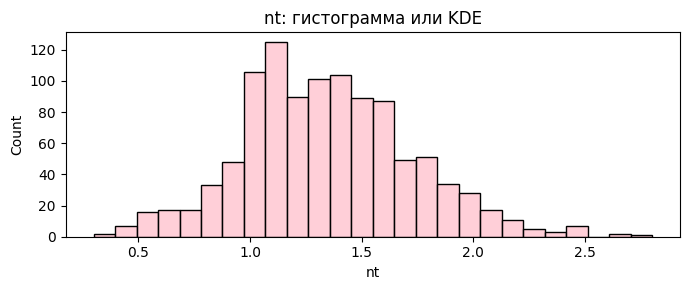

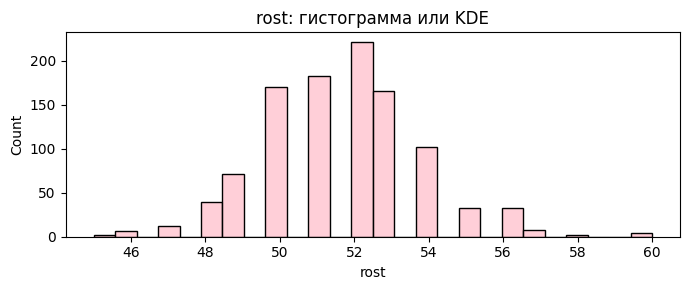

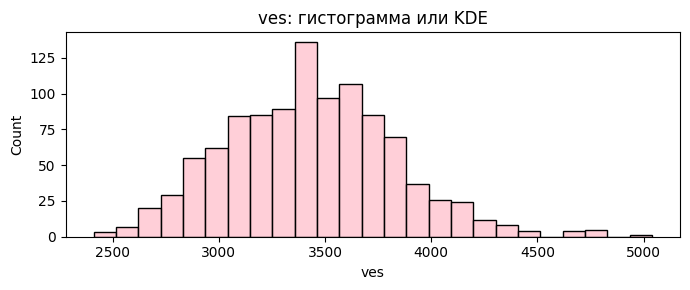

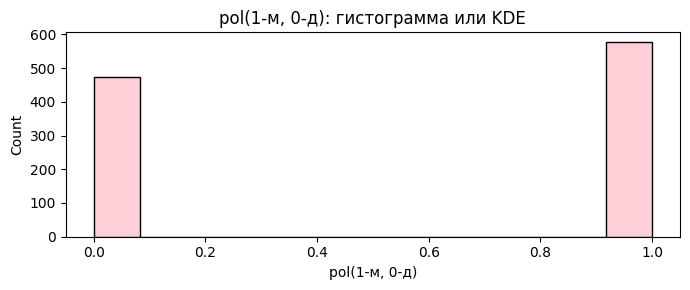

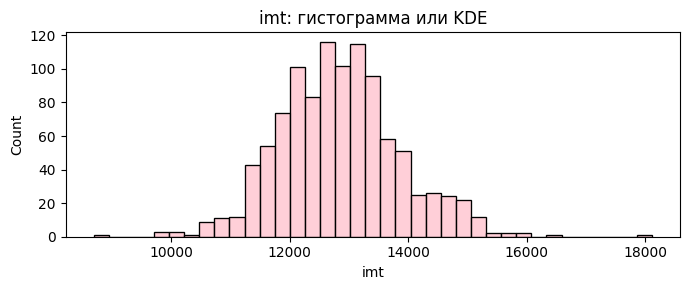

In [6]:
for col in numeric_cols:
    plt.figure(figsize=(7, 3))
    sns.histplot(df[col], color='pink')
    plt.title(f'{col}: гистограмма или KDE')
    plt.tight_layout()
    plt.show()

**Для нормального распределения:**
* Асимметрия **≈ 0**
* Эксцесс  **≈ 0**

In [7]:
skew_kurt = pd.DataFrame({
    'Асимметрия (skew)': df[numeric_cols].skew().round(3),
    'Эксцесс (kurtosis)': df[numeric_cols].kurtosis().round(3)
})
display(skew_kurt)



,Асимметрия (skew),Эксцесс (kurtosis)
vozrast,0.279,-0.596
gr-dni,0.163,-0.350
ctr,0.036,-0.817
nt,0.330,0.303
rost,0.231,0.819
ves,0.326,0.385
"pol(1-м, 0-д)",-0.199,-1.964
imt,0.291,0.944


In [8]:
alpha = 0.05
norm_results = []
for col in numeric_cols:
    data = df[col].dropna()
    stat, p = stats.shapiro(data)
    conclusion = "не нормально (но отвергается)" if p < alpha else "Похоже на нормальное (H0 не отвергается)"
    norm_results.append({'Показатель': col, 'W-статистика': round(stat, 4),
                         'p-value': round(p, 4), 'Вывод (α=0.05)': conclusion})

norm_df = pd.DataFrame(norm_results)
display(norm_df)


,Показатель,W-статистика,p-value,Вывод (α=0.05)
0,vozrast,0.9808,0.0,не нормально (но отвергается)
1,gr-dni,0.9927,0.0,не нормально (но отвергается)
2,ctr,0.9774,0.0,не нормально (но отвергается)
3,nt,0.9858,0.0,не нормально (но отвергается)
4,rost,0.9727,0.0,не нормально (но отвергается)
5,ves,0.9910,0.0,не нормально (но отвергается)
6,"pol(1-м, 0-д)",0.6330,0.0,не нормально (но отвергается)
7,imt,0.9903,0.0,не нормально (но отвергается)


    6. Исследовать гендерные различия антропометрических параметров новорождённых:
        a. находим средний рост отдельно для мальчиков и отдельно для девочек и проверяем, есть ли гендерные различия (Т-тест на сравнение средних – выбираем правильный!!!)
        b. вес
        c. ИМТ

In [9]:
male = df[df['pol(1-м, 0-д)'] == 1]
female = df[df['pol(1-м, 0-д)'] == 0]

alpha = 0.05
metrics = ['rost', 'ves', 'imt']
rows = []

for m in metrics:
    t_stat, p = stats.ttest_ind(male[m].dropna(), female[m].dropna(), equal_var=False)
    conclusion = "Различия есть (но отвергается)" if p < alpha else "Различий нет (но не отвергается)"
    rows.append({
        'Показатель': m,
        'Ср.знач (мальчики)': round(male[m].mean(), 2),
        'Ср.знач (девочки)': round(female[m].mean(), 2),
        't-статистика': round(t_stat, 3),
        'p-value': round(p, 4),
        'Вывод (α=0.05)': conclusion
    })

display(pd.DataFrame(rows))

,Показатель,Ср.знач (мальчики),Ср.знач (девочки),t-статистика,p-value,Вывод (α=0.05)
0,rost,52.00,51.33,5.297,0.0000,Различия есть (но отвергается)
1,ves,3497.46,3360.54,5.678,0.0000,Различия есть (но отвергается)
2,imt,12906.16,12736.87,2.705,0.0069,Различия есть (но отвергается)
